# 13 — Validate FIRMS detections against source L2 fire pixels

This notebook inspects the two real granules selected in notebook 12. It verifies download checksums, reads VIIRS NetCDF4/HDF5 with `h5py` and Aqua MODIS HDF4 with `pyhdf`, finds each FIRMS point's nearest active-fire pixel record, and checks the corresponding fire-mask class. It preserves product-specific confidence semantics. A close source-pixel match supports row-to-granule lineage; it does not prove the two sensors observed one physical fire or validate false-alarm rates.

Run from the project root after the bounded download finishes and dependencies are installed from `requirements.txt`.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.firewatch.swath_validation import inspect_modis_granule, inspect_viirs_granule, summarize_match
PLAN=ROOT/'data/reference/cmr_sample_plan_oct2025.csv'
PILOT=ROOT/'data/reference/granules/oct2025_pilot'
DOWNLOAD_MANIFEST=PILOT/'download_manifest.json'
plan=pd.read_csv(PLAN)
download_meta=json.loads(DOWNLOAD_MANIFEST.read_text(encoding='utf-8'))
assert len(plan)==2 and download_meta['download_count']==2
by_name={item['filename']:item for item in download_meta['downloads']}
for filename, item in by_name.items():
    path=PILOT/filename
    assert path.is_file() and path.stat().st_size==item['bytes']
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual==item['sha256'], f'Checksum mismatch for {filename}'
print('Verified both downloaded granules against the SHA-256 download manifest.')
print(plan[['satellite','product_code','observation_time_utc','observation_latitude','observation_longitude','producer_granule_id']].to_string(index=False))

Verified both downloaded granules against the SHA-256 download manifest.
satellite product_code      observation_time_utc  observation_latitude  observation_longitude                      producer_granule_id
     Aqua        M-C61 2025-10-20T13:26:00+00:00              11.01460               13.85750    MYD14.A2025293.1325.061.2025294143419
     SNPP        SV-C2 2025-10-20T13:10:00+00:00              11.01529               13.86254 VNP14IMG.A2025293.1306.002.2025293205847


In [2]:
results=[]
for row in plan.itertuples(index=False):
    if row.short_name=='MYD14':
        path=PILOT/f'{row.producer_granule_id}.hdf'
        result=inspect_modis_granule(path, observation_latitude=row.observation_latitude, observation_longitude=row.observation_longitude)
    elif row.short_name=='VNP14IMG':
        path=PILOT/f'{row.producer_granule_id}.nc'
        result=inspect_viirs_granule(path, observation_latitude=row.observation_latitude, observation_longitude=row.observation_longitude)
    else:
        raise ValueError(f'Unexpected product in bounded plan: {row.short_name}')
    result.update({
        'observation_id':row.observation_id,
        'observation_time_utc':row.observation_time_utc,
        'csv_latitude':row.observation_latitude,
        'csv_longitude':row.observation_longitude,
        'candidate_link_id':row.candidate_link_id,
        'candidate_edge_distance_km':row.edge_distance_km,
        'candidate_edge_time_difference_minutes':row.edge_time_difference_minutes,
    'observation_time_in_granule': pd.Timestamp(result['start_time']).tz_localize('UTC') <= pd.Timestamp(row.observation_time_utc) <= pd.Timestamp(result['end_time']).tz_localize('UTC'),
    })
    results.append(result)
summary=pd.DataFrame(results)
display(summary[['product','satellite','collection_version','process_version','confidence_semantics','start_time','end_time','observation_time_in_granule','active_fire_pixel_count','distance_km','fire_pixel_latitude','fire_pixel_longitude','confidence_code_or_percent','fire_mask_class','frp_mw','line','sample']])
print('\n'+'\n'.join(summarize_match(item) for item in results))

,product,satellite,collection_version,process_version,confidence_semantics,start_time,end_time,observation_time_in_granule,active_fire_pixel_count,distance_km,fire_pixel_latitude,fire_pixel_longitude,confidence_code_or_percent,fire_mask_class,frp_mw,line,sample
0,MYD14,Aqua,61,6.2.3,Percent (0–100); fire-mask class carries low/n...,2025-10-20T13:25:00.000000,2025-10-20T13:30:00.000000,True,262,0.004711,11.014639,13.857483,50,8,29.827133,786,1245
1,VNP14IMG,SUOMI-NPP,002,3.1.9,"Categorical code: 7 low, 8 nominal, 9 high",2025-10-20 13:06:00.000,2025-10-20 13:12:00.000,True,818,0.000396,11.015286,13.862540,8,8,4.300107,5397,490



MYD14 nearest L2 fire-pixel record is 0.0047 km from the FIRMS point; mask class 8, FRP 29.827 MW.
VNP14IMG nearest L2 fire-pixel record is 0.0004 km from the FIRMS point; mask class 8, FRP 4.300 MW.


In [3]:
# Integrity/consistency checks for this immutable pilot sample.
assert all(r['distance_km'] < 0.05 for r in results), 'At least one FIRMS point is >50 m from its nearest L2 fire-pixel record'
assert all(r['fire_mask_class'] in {7,8,9} for r in results), 'Nearest active-fire list record does not map to fire mask class 7–9'
assert {r['product'] for r in results} == {'MYD14','VNP14IMG'}
assert all(r['observation_time_in_granule'] for r in results), 'CSV observation time falls outside selected product granule interval'
print('Both FIRMS coordinates resolve to a nominal-or-other-confidence active-fire mask cell within 50 m.')
print('MODIS FP_confidence is a percent; VIIRS FP_confidence is a category code. Do not compare these numerically.')
print('FRP values are reported separately by sensor; they are not assumed to be cross-calibrated.')

Both FIRMS coordinates resolve to a nominal-or-other-confidence active-fire mask cell within 50 m.
MODIS FP_confidence is a percent; VIIRS FP_confidence is a category code. Do not compare these numerically.
FRP values are reported separately by sensor; they are not assumed to be cross-calibrated.


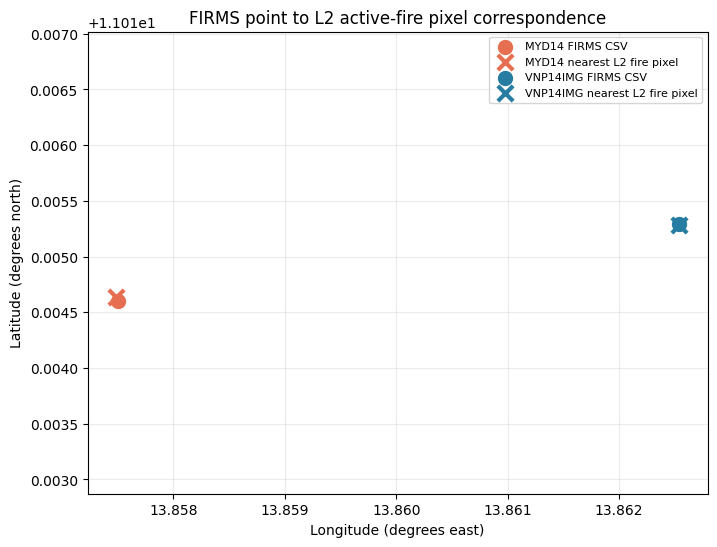

Saved source-pixel comparison:

 data\processed\source_pixel_validation_oct2025.csv


In [4]:
# Plot the two actual source detections and their closest L2 fire-pixel positions.
fig, ax=plt.subplots(figsize=(8,6))
colors={'MYD14':'#e76f51','VNP14IMG':'#277da1'}
for r in results:
    c=colors[r['product']]
    ax.scatter(r['csv_longitude'],r['csv_latitude'],s=100,marker='o',color=c,label=f"{r['product']} FIRMS CSV")
    ax.scatter(r['fire_pixel_longitude'],r['fire_pixel_latitude'],s=120,marker='x',linewidth=3,color=c,label=f"{r['product']} nearest L2 fire pixel")
ax.set_xlabel('Longitude (degrees east)'); ax.set_ylabel('Latitude (degrees north)')
ax.set_title('FIRMS point to L2 active-fire pixel correspondence')
ax.grid(alpha=.25); ax.legend(fontsize=8); ax.set_aspect('equal',adjustable='datalim'); plt.show()
OUT=ROOT/'data/processed/source_pixel_validation_oct2025.csv'
summary.to_csv(OUT,index=False)
print('Saved source-pixel comparison:',OUT.relative_to(ROOT))

## Interpretation and limits

The closest fire-pixel record and the fire mask provide a direct product-internal check for each selected coordinate. The two positive pixel correspondences support the catalog time/polygon linkage for this small pilot. The initial cross-satellite edge remains a candidate association: these two files alone do not establish event identity, measure detection accuracy, estimate false alarms, or provide a harmonized fire count. MODIS confidence is a percentage while VIIRS confidence is a categorical code; FRP values also remain source-specific. This pilot is selected around one existing candidate, so it is not an unbiased validation sample.